In [16]:
#imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import time
import joblib
import warnings
import zipfile
warnings.filterwarnings('ignore')
import cv2


from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

pd.set_option('display.max_columns', None)
plt.style.use('ggplot')

In [21]:
dataset_path = 'E:\BrainTumor_ML_Model\Datasets'
for root, dirs, files in os.walk(dataset_path):
    print(root)

E:\BrainTumor_ML_Model\Datasets
E:\BrainTumor_ML_Model\Datasets\Testing
E:\BrainTumor_ML_Model\Datasets\Testing\glioma
E:\BrainTumor_ML_Model\Datasets\Testing\meningioma
E:\BrainTumor_ML_Model\Datasets\Testing\notumor
E:\BrainTumor_ML_Model\Datasets\Testing\pituitary
E:\BrainTumor_ML_Model\Datasets\Training
E:\BrainTumor_ML_Model\Datasets\Training\glioma
E:\BrainTumor_ML_Model\Datasets\Training\meningioma
E:\BrainTumor_ML_Model\Datasets\Training\notumor
E:\BrainTumor_ML_Model\Datasets\Training\pituitary


In [22]:
train_path = os.path.join(dataset_path, 'Training')
test_path = os.path.join(dataset_path, 'Testing')

classes = sorted(os.listdir(train_path))

print("Classes Found")
print(classes)

Classes Found
['glioma', 'meningioma', 'notumor', 'pituitary']


In [23]:
train_count = {}
test_count = {}

for cls in classes:
    train_count[cls] = len(os.listdir(os.path.join(train_path, cls)))
    test_count[cls] = len(os.listdir(os.path.join(test_path, cls)))

train_df = pd.DataFrame({"Training" : train_count, "Testing" : test_count})

train_df

,Training,Testing
glioma,1400,400
meningioma,1400,400
notumor,1400,400
pituitary,1400,400


In [24]:
import os

for root, dirs, files in os.walk(extract_path):
    print(root)

In [26]:
dataset_path = "E:\BrainTumor_ML_Model\Datasets"

train_path = os.path.join(dataset_path, "Training")
test_path = os.path.join(dataset_path, "Testing")

classes = sorted(os.listdir(train_path))

print(classes)

['glioma', 'meningioma', 'notumor', 'pituitary']


In [27]:
train_count = {}
test_count = {}

for cls in classes:
    train_count[cls] = len(os.listdir(os.path.join(train_path, cls)))
    test_count[cls] = len(os.listdir(os.path.join(test_path, cls)))

train_df = pd.DataFrame({"Training" : train_count, "Testing" : test_count})

train_df


,Training,Testing
glioma,1400,400
meningioma,1400,400
notumor,1400,400
pituitary,1400,400


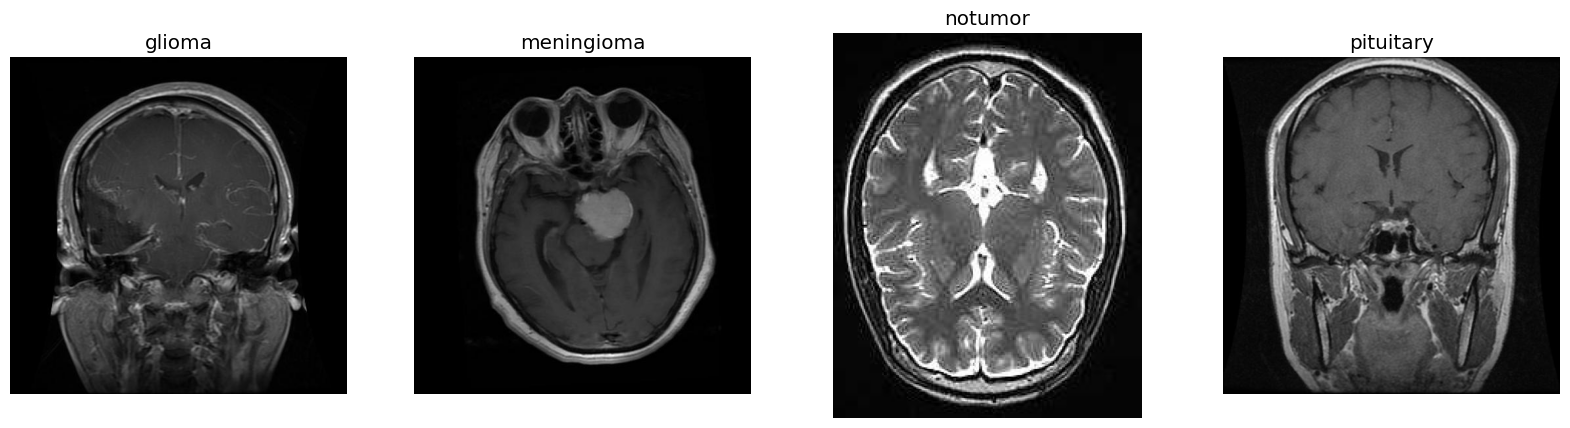

In [28]:
fig, axes = plt.subplots(1, len(classes), figsize=(20, 5))

for i, cls in enumerate(classes):
    img_path = os.path.join(train_path, cls, os.listdir(os.path.join(train_path, cls))[0])

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    axes[i].imshow(img)
    axes[i].set_title(cls)
    axes[i].axis('off')

In [29]:
IMG_SIZE = 128

def preprocess_image(image_path):
    image = cv2.imread(image_path)
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return gray

In [30]:
def extract_hog(image):
    features = hog(image, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm='L2-Hys', feature_vector=True)
    return features

In [31]:
RADIUS = 2
N_POINTS = 8 * RADIUS

def extract_lbp(image):

    lbp = local_binary_pattern(image, N_POINTS, RADIUS, method='uniform')

    hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, N_POINTS + 3), range=(0, N_POINTS + 2))
    hist = hist.astype("float")
    hist /=  (hist.sum() + 1e-7)
    return hist

In [32]:
def extract_glcm(image):

    glcm = graycomatrix(
        image,
        distances=[1],
        angles=[0],
        levels=256,
        symmetric=True
    )
    contrast = graycoprops(glcm, 'contrast')[0, 0]
    dissimilarity = graycoprops(glcm, 'dissimilarity')[0, 0]
    homogenity = graycoprops(glcm, 'homogeneity')[0, 0]
    energy = graycoprops(glcm, 'energy')[0, 0]
    correlation = graycoprops(glcm, 'correlation')[0, 0]
    asm = graycoprops(glcm, 'ASM')[0, 0]
    return np.array([
        contrast,
        dissimilarity,
        homogenity,
        energy,
        correlation,
        asm
    ])

In [17]:
def extract_features(image_path):
    image = preprocess_image(image_path)
    hog_features = extract_hog(image)
    lbp_features = extract_lbp(image)
    glcm_features = extract_glcm(image)
    return np.concatenate([hog_features, lbp_features, glcm_features])

In [34]:
X = []
y = []
for cls in classes:
    folder = os.path.join(train_path, cls)

    print(f"Loading {cls}...")

    for image_name in os.listdir(folder):
        image_path = os.path.join(folder, image_name)

        try:
            features = extract_features(image_path)

            X.append(features)
            y.append(cls)

        except:
            continue

Loading glioma...
Loading meningioma...
Loading notumor...
Loading pituitary...


In [35]:
X_test = []
y_test = []
for cls in classes:
    folder = os.path.join(test_path, cls)

    print(f"Loading {cls}...")

    for image_name in os.listdir(folder):
        image_path = os.path.join(folder, image_name)

        try:
            features = extract_features(image_path)

            X_test.append(features)
            y_test.append(cls)

        except:
            continue

Loading glioma...
Loading meningioma...
Loading notumor...
Loading pituitary...


In [36]:
X = np.array(X)
X_test = np.array(X_test)

y = np.array(y)
y_test = np.array(y_test)

print("Training Shape : ", X.shape)
print("Testing Shape : ", X_test.shape)

Training Shape :  (5600, 8124)
Testing Shape :  (1600, 8124)


In [37]:
from sklearn.preprocessing import LabelEncoder


encoder = LabelEncoder()
y = encoder.fit_transform(y)
y_test = encoder.transform(y_test)
print("Classes")
for i, cls in enumerate(encoder.classes_):
    print(i, "->", cls)

Classes
0 -> glioma
1 -> meningioma
2 -> notumor
3 -> pituitary


In [38]:
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()
X = scaler.fit_transform(X)
X_test = scaler.transform(X_test)
print("Scaling Completed")

Scaling Completed


In [39]:
print("="*60)
print("Training samples: ", X.shape[0])
print("Testing samples: ", X_test.shape[0])
print("Number of features: ", X.shape[1])
print("Classes: ", len(np.unique(y)))
print("="*60)

Training samples:  5600
Testing samples:  1600
Number of features:  8124
Classes:  4


In [22]:
print("skip")
# models = {
#     # "SVM": SVC(
#     #     kernel = 'rbf',
#     #     C=10,
#     #     gamma='scale',
#     #     probability=True,
#     #     random_state=42
#     # ),

#     # "Random Forest": RandomForestClassifier(
#     #     n_estimators=300,
#     #     random_state=42,
#     #     n_jobs=-1
#     # ),
#     # "Extra Trees": ExtraTreesClassifier(
#     #     n_estimators=300,
#     #     random_state=42,
#     #     n_jobs=-1
#     # ),

#     "XGBoost": XGBClassifier(
#         n_estimators=300,
#         learning_rate=0.05,
#         max_depth=6,
#         subsample=0.8,
#         colsample_bytree=0.8,
#         random_state=42,
#         eval_metric='mlogloss'
#     ),

#     # "CatBoost": CatBoostClassifier(
#     #     iterations=300,
#     #     learning_rate=0.05,
#     #     depth=6,
#     #     verbose=0,
#     #     random_state=42
#     # )
# }

# print(models.keys())

skip


In [23]:
from sklearn.svm import SVC

models = {

    "SVM": SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        probability=True,
        random_state=42
    )
}

print(models.keys())

dict_keys(['SVM'])


In [24]:
results=[]
trained_models = {}

Training Model : SVM

Running 5-Fold Cross Validation...

Model Performance
----------------------------------------
Accuracy       : 0.9075
Precision      : 0.9158
Recall         : 0.9075
F1 Score       : 0.9040
CV Accuracy    : 0.9452
Training Time  : 396.29 seconds

Classification Report

              precision    recall  f1-score   support

      glioma       0.98      0.70      0.82       400
  meningioma       0.85      0.95      0.89       400
     notumor       0.87      1.00      0.93       400
   pituitary       0.96      0.98      0.97       400

    accuracy                           0.91      1600
   macro avg       0.92      0.91      0.90      1600
weighted avg       0.92      0.91      0.90      1600



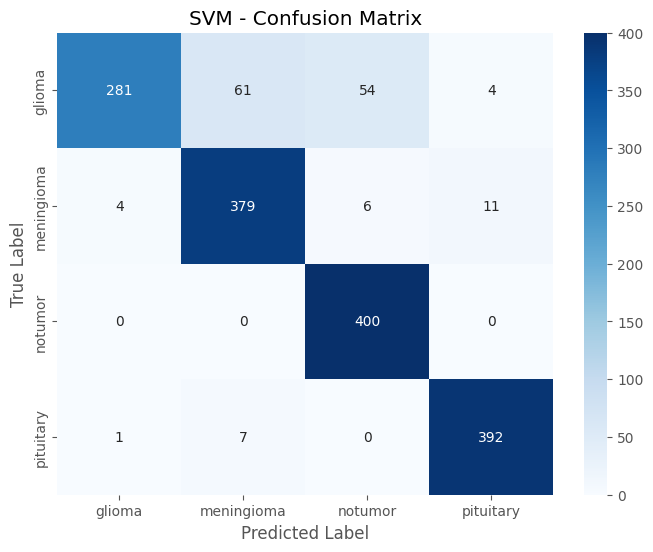


Final Results


,Model,Accuracy,Precision,Recall,F1 Score,CV Accuracy,Training Time (sec)
0,SVM,0.9075,0.915776,0.9075,0.903974,0.945179,396.287179


In [25]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

results = []
trained_models = {}

for name, model in models.items():

    print("=" * 70)
    print(f"Training Model : {name}")

    # ---------------- Train ----------------
    start = time.time()

    model.fit(X, y)

    training_time = time.time() - start

    trained_models[name] = model

    # ---------------- Prediction ----------------
    predictions = model.predict(X_test)

    # ---------------- Evaluation ----------------
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, average="weighted")
    recall = recall_score(y_test, predictions, average="weighted")
    f1 = f1_score(y_test, predictions, average="weighted")

    # ---------------- Cross Validation ----------------
    print("\nRunning 5-Fold Cross Validation...")

    cv_score = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring="accuracy",
        n_jobs=1      # Recommended for SVM
    ).mean()

    # ---------------- Store Results ----------------
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "CV Accuracy": cv_score,
        "Training Time (sec)": training_time
    })

    # ---------------- Print Results ----------------
    print("\nModel Performance")
    print("-" * 40)
    print(f"Accuracy       : {accuracy:.4f}")
    print(f"Precision      : {precision:.4f}")
    print(f"Recall         : {recall:.4f}")
    print(f"F1 Score       : {f1:.4f}")
    print(f"CV Accuracy    : {cv_score:.4f}")
    print(f"Training Time  : {training_time:.2f} seconds")

    # ---------------- Classification Report ----------------
    print("\nClassification Report\n")

    print(
        classification_report(
            y_test,
            predictions,
            target_names=encoder.classes_
        )
    )

    # ---------------- Confusion Matrix ----------------
    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=encoder.classes_,
        yticklabels=encoder.classes_
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

    plt.show()

# ---------------- Final Results ----------------
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("\nFinal Results")
display(results_df)

In [26]:
#comparision Table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

results_df.reset_index(drop=True, inplace=True)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,CV Accuracy,Training Time (sec)
0,SVM,0.9075,0.915776,0.9075,0.903974,0.945179,396.287179


In [42]:
# Save all the results
results_df.to_csv(
    "Model_Comparison.csv",
    index=False
)

print("Comparison saved successfully.")

NameError: name 'results_df' is not defined

In [41]:
# Select the best model
best_model_name = results_df.iloc[0]["Model"]

print("Best Model :", best_model_name)

best_model = trained_models[best_model_name]

NameError: name 'results_df' is not defined

In [30]:
# Save the best model
joblib.dump(best_model, "Best_BrainTumor_Model.pkl")
joblib.dump(scaler, "Scaler.pkl")
joblib.dump(encoder, "LabelEncoder.pkl")
print("Best model saved successfully.")

Best model saved successfully.


In [40]:
# Classification Report
prediction = best_model.predict(X_test)

print(classification_report(
    y_test,
    prediction,
    target_names=encoder.classes_
))

NameError: name 'best_model' is not defined

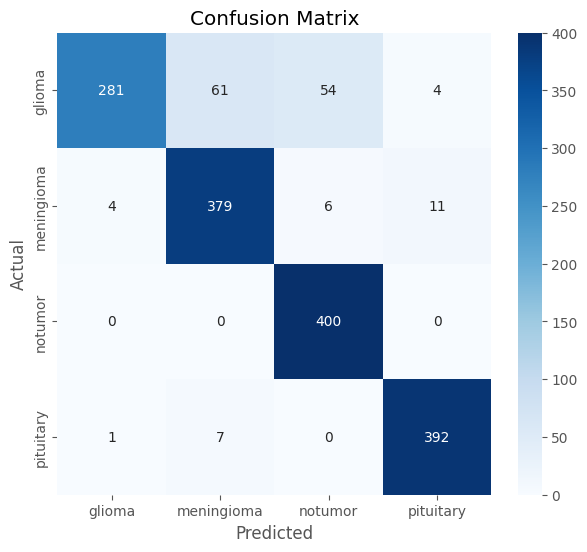

In [32]:
# confusion matrix
cm = confusion_matrix(y_test, prediction)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [10]:
# Lode Saved files
import joblib

# Load saved artifacts
model = joblib.load("Best_BrainTumor_Model.pkl")
scaler = joblib.load("Scaler.pkl")
encoder = joblib.load("LabelEncoder.pkl")

print("Model loaded successfully.")

FileNotFoundError: [Errno 2] No such file or directory: 'Best_BrainTumor_Model.pkl'

In [11]:
# feature extraction for single image
def prepare_single_image(image_path):
    """
    Extract features from a single image
    """

    features = extract_features(image_path)

    features = features.reshape(1, -1)

    features = scaler.transform(features)

    return features

In [12]:
# Prediction function
def predict_brain_tumor(image_path):

  
    features = prepare_single_image(image_path)


    prediction = model.predict(features)


    probabilities = model.predict_proba(features)

    predicted_class = encoder.inverse_transform(prediction)[0]

    confidence = np.max(probabilities) * 100

    return predicted_class, confidence

In [12]:
import os

os.makedirs("saved_model", exist_ok=True)

joblib.dump(best_model, "saved_model/Best_BrainTumor_Model.pkl")
joblib.dump(scaler, "saved_model/Scaler.pkl")
joblib.dump(encoder, "saved_model/LabelEncoder.pkl")

print("Model saved successfully.")

NameError: name 'best_model' is not defined

In [13]:
import joblib

model = joblib.load("saved_model/Best_BrainTumor_Model.pkl")
scaler = joblib.load("saved_model/Scaler.pkl")
encoder = joblib.load("saved_model/LabelEncoder.pkl")

print("Model loaded successfully.")

FileNotFoundError: [Errno 2] No such file or directory: 'saved_model/Best_BrainTumor_Model.pkl'

In [14]:
def prepare_single_image(image_path):

    if not os.path.exists(image_path):
        raise FileNotFoundError(f"{image_path} not found.")

    features = extract_features(image_path)
    features = features.reshape(1, -1)
    features = scaler.transform(features)

    return features

In [15]:
def predict_brain_tumor(image_path):

    features = prepare_single_image(image_path)

    prediction = model.predict(features)
    probabilities = model.predict_proba(features)[0]

    predicted_class = encoder.inverse_transform(prediction)[0]

    confidence = np.max(probabilities) * 100

    probability_dict = {}

    for cls, prob in zip(encoder.classes_, probabilities):
        probability_dict[cls] = round(prob * 100, 2)

    return predicted_class, confidence, probability_dict

In [40]:
import os

folder = "/content/Datasets/Datasets/Testing/notumor"

print(os.listdir(folder)[:800])

['Te-no_349.jpg', 'Te-no_161.jpg', 'Te-no_320.jpg', 'Te-no_149.jpg', 'Te-no_350.jpg', 'Te-no_344.jpg', 'Te-no_27.jpg', 'Te-no_3.jpg', 'Te-no_260.jpg', 'Te-no_272.jpg', 'Te-no_271.jpg', 'Te-no_92.jpg', 'Te-no_181.jpg', 'Te-no_340.jpg', 'Te-no_38.jpg', 'Te-no_44.jpg', 'Te-no_68.jpg', 'Te-no_175.jpg', 'Te-no_231.jpg', 'Te-no_144.jpg', 'Te-no_53.jpg', 'Te-no_1.jpg', 'Te-no_358.jpg', 'Te-no_41.jpg', 'Te-no_14.jpg', 'Te-no_310.jpg', 'Te-no_379.jpg', 'Te-no_359.jpg', 'Te-no_166.jpg', 'Te-no_185.jpg', 'Te-no_288.jpg', 'Te-no_331.jpg', 'Te-no_292.jpg', 'Te-no_399.jpg', 'Te-no_332.jpg', 'Te-no_269.jpg', 'Te-no_224.jpg', 'Te-no_157.jpg', 'Te-no_30.jpg', 'Te-no_147.jpg', 'Te-no_309.jpg', 'Te-no_230.jpg', 'Te-no_127.jpg', 'Te-no_243.jpg', 'Te-no_5.jpg', 'Te-no_189.jpg', 'Te-no_180.jpg', 'Te-no_4.jpg', 'Te-no_257.jpg', 'Te-no_287.jpg', 'Te-no_43.jpg', 'Te-no_124.jpg', 'Te-no_198.jpg', 'Te-no_360.jpg', 'Te-no_218.jpg', 'Te-no_213.jpg', 'Te-no_262.jpg', 'Te-no_389.jpg', 'Te-no_173.jpg', 'Te-no_279.jpg

In [7]:
image_path = "E:\BrainTumor_ML_Model\Datasets\Testing\glioma\Te-gl_1.jpg"

<>:1: SyntaxWarning: invalid escape sequence '\B'
<>:1: SyntaxWarning: invalid escape sequence '\B'
C:\Users\jishn\AppData\Local\Temp\ipykernel_20500\2770496924.py:1: SyntaxWarning: invalid escape sequence '\B'
  image_path = "E:\BrainTumor_ML_Model\Datasets\Testing\glioma\Te-gl_1.jpg"


In [16]:
import cv2

# Read image
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Predict
prediction, confidence, probabilities = predict_brain_tumor(image_path)

# Display image
plt.figure(figsize=(6, 6))
plt.imshow(image_rgb)
plt.axis("off")

plt.title(
    f"Prediction: {prediction.upper()}\nConfidence: {confidence:.2f}%",
    fontsize=15,
    color="green",
    fontweight="bold"
)

plt.show()

# Display prediction
print(f"Predicted Class : {prediction}")
print(f"Confidence      : {confidence:.2f}%")

print("\nClass Probabilities")
print("-" * 35)

for cls, prob in probabilities.items():
    print(f"{cls.capitalize():12s}: {prob:.2f}%")

NameError: name 'extract_features' is not defined

In [4]:
import joblib

model = joblib.load("../saved_models/Best_BrainTumor_Model.pkl")
scaler = joblib.load("../saved_models/Scaler.pkl")
encoder = joblib.load("../saved_models/LabelEncoder.pkl")

print("Models loaded successfully.")

Models loaded successfully.


c:\Users\jishn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SVC from version 1.6.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\jishn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\jishn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LabelEnc

In [3]:
print(os.listdir())

['Brain_Tumor_Model.ipynb']
